# Predicting serious food-safety violations in Seattle restaurants

**Summary**

The asian and ethnic flags look like the strongest predictor in this data, but I don't think they can be trusted. The scores for Asian and other ethnic restaurants don't behave like real inspection records (section 2.2), so most of the model's accuracy comes from that label problem. For the other restaurants, where the records look fine, the best model gets an AUC of 0.66, only a bit better than ranking by the last inspection score (0.64). Inspection history does almost all the work and Yelp adds nothing. Used as it is, the model would send every priority inspection to Asian and ethnic restaurants, which is the main thing I'd want a health department to know before using something like this.

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.precision", 3)

## 0. Load/check the data

Each row is one inspection, not one restaurant. It has the inspection's penalty score plus what was known before it: the previous score, an average of earlier scores, and the Yelp reviews since the last inspection.

In [2]:
df = pd.read_csv("data/food_violations_seattle.csv", index_col=0,
                 parse_dates=["inspection_period_start_date", "inspection_period_end_date"])
lookup = pd.read_csv("data/cuisines.csv", index_col="x")

# shorter column names
df = df.rename(columns={
    "inspection_period_start_date": "period_start",
    "inspection_period_end_date": "inspection_date",
    "inspection_penalty_score": "score",
    "inspection_prev_penalty_score": "prev_score",
    "inspection_average_prev_penalty_scores": "avg_prev_score",
    "average_review_rating": "avg_rating",
    "review_contents": "review_text",
})

# quick sanity checks
assert df.inspection_id.is_unique
assert df.notna().all().all()
assert (df.period_start < df.inspection_date).all()

print(len(df), "inspections,", df.restaurant_id.nunique(), "restaurants,",
      df.inspection_date.min().date(), "to", df.inspection_date.max().date())
df.drop(columns="review_text").head(3)

13299 inspections, 1756 restaurants, 2006-01-03 to 2013-02-08


,inspection_id,restaurant_id,period_start,inspection_date,score,avg_prev_score,prev_score,cuisines,zip_code,review_count,non_positive_review_count,avg_rating
0,DA2383404,ZriNDCVxkCdVEO-X2sjHFw,2012-02-06,2012-10-02,46,54.0,50,"['Japanese', 'Restaurants']",98116,1,0,5.000
1,DA2304227,ZriNDCVxkCdVEO-X2sjHFw,2011-11-03,2012-02-06,82,86.0,76,"['Japanese', 'Restaurants']",98116,3,0,4.000
2,DA2278690,ZriNDCVxkCdVEO-X2sjHFw,2011-01-06,2011-11-03,24,67.0,41,"['Japanese', 'Restaurants']",98116,7,0,4.429


Two rows have a -1 placeholder. One inspection scored -1 and the next one at the same restaurant carries it as its previous score. Scores can't be negative, so I drop both.

In [3]:
bad = (df[["score", "prev_score", "avg_prev_score"]] < 0).any(axis=1)
display(df.loc[bad, ["restaurant_id", "inspection_date", "score", "prev_score", "avg_prev_score"]])

df = df[~bad].copy()
df["serious"] = (df.score >= 10).astype(int)
print(len(df), "inspections left")
print(df.duplicated(["restaurant_id", "inspection_date"], keep=False).sum(),
      "rows share a restaurant and date with another row (different inspection IDs, so I keep them)")

,restaurant_id,inspection_date,score,prev_score,avg_prev_score
9049,DRpffXwLMlMqKN_QX2a0vw,2012-11-27,0,-1,-1.0
9050,DRpffXwLMlMqKN_QX2a0vw,2012-04-10,-1,0,0.0


13297 inspections left
171 rows share a restaurant and date with another row (different inspection IDs, so I keep them)


## 1. How spread out are the violation scores?

### 1.1 The overall distribution

I want to see how many inspections are clean, how long the tail is and where the cutoff of 10 falls, since all three affect how I model this.

count    13297.000
mean        32.081
std         29.769
min          0.000
25%          5.000
50%         25.000
75%         57.000
max        124.000
Name: score, dtype: float64
share scoring 0: 0.217
share serious (10+): 0.674


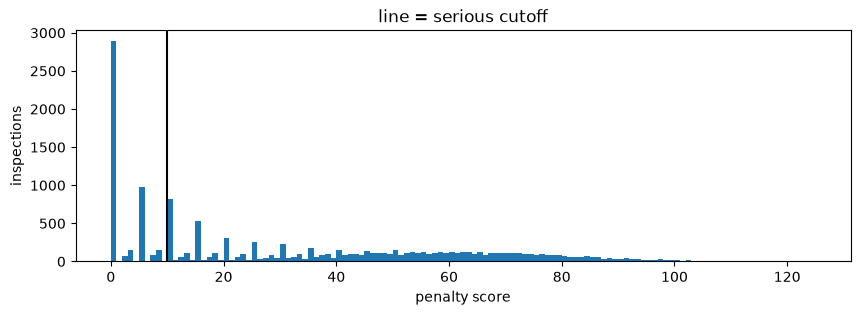

In [4]:
print(df.score.describe())
print("share scoring 0:", round((df.score == 0).mean(), 3))
print("share serious (10+):", round(df.serious.mean(), 3))

plt.figure(figsize=(10, 3))
plt.hist(df.score, bins=range(0, 126))
plt.axvline(10, color="black")
plt.title("line = serious cutoff")
plt.xlabel("penalty score")
plt.ylabel("inspections")
plt.show()

Three things stand out:
1. 22% of inspections score exactly 0: the distribution is a spike at zero followed by a long tail up to 124.
2. Below about 45 the scores bunch on multiples of 5 (0, 5, 10, 15 and so on), while above 45 they spread smoothly across every value. Section 2 shows where that smooth hump comes from.
3. The cutoff of 10 sits low. 67% count as serious, so the label separates the cleanest third from everyone else rather than flagging rare, dangerous inspections. This is also why accuracy is not that helpful here. Calling every inspection serious is already right 67% of the time.

### 1.2 Scores spread across restaurants, and whether they stick or not

The prompt asks about the spread among restaurants, so I also look at each restaurant's average score and how often it was serious. If a restaurant's past predicts its next inspection, history alone can guide targeting. This also shapes how to test the model. Since a restaurant's rows are related, splitting them at random would let a model learn from a restaurant's later inspections and then be graded on its earlier ones.

In [5]:
by_restaurant = df.groupby("restaurant_id").agg(avg_score=("score", "mean"), share_serious=("serious", "mean"))
print(by_restaurant.avg_score.describe())
print("never serious:", round((by_restaurant.share_serious == 0).mean(), 3))
print("serious every time:", round((by_restaurant.share_serious == 1).mean(), 3))
print("corr with previous score:", round(df.score.corr(df.prev_score), 3))

restaurant_mean = df.groupby("restaurant_id").score.transform("mean")
print("share of variance explained by restaurant:", round(restaurant_mean.var() / df.score.var(), 3))

count    1755.000
mean       30.566
std        26.509
min         0.000
25%         6.612
50%        17.000
75%        58.374
max       108.000
Name: avg_score, dtype: float64
never serious: 0.119
serious every time: 0.449
corr with previous score: 0.707
share of variance explained by restaurant: 0.751


Restaurants differ a lot.
1. The typical restaurant averages 17 points, but a quarter average under 7 and a quarter average over 58.
2. 12% of restaurants never had a serious inspection, while 45% were serious at every one.
3. Scores also stick to restaurants: the correlation with the previous score is 0.71, and which restaurant it is explains about three quarters of the variation. So inspection history should predict well, and a fair test has to keep each restaurant's later inspections out of training.

### 1.3 History, time, place and Yelp

Each chart shows the share of inspections that were serious, split one way:
1. **Previous score** shows the history signal.
2. **Year** checks for a trend, which would change how to test.
3. **Zip code** matters because location can stand in for who owns, works at or eats at a restaurant.
4. **Yelp rating** tests the idea behind earlier work on this data (Kang et al., 2013) that online reviews reveal hygiene. The gray line is the overall share.

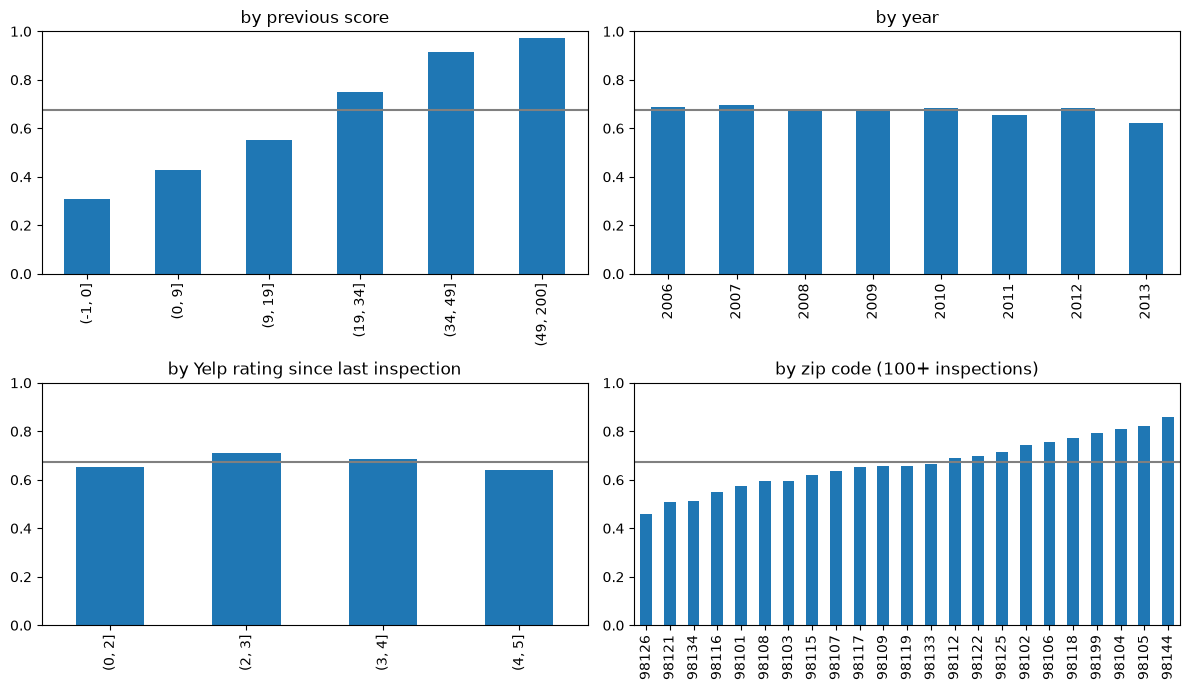

prev_score
(-1, 0]      0.308
(0, 9]       0.428
(9, 19]      0.551
(19, 34]     0.749
(34, 49]     0.913
(49, 200]    0.974
Name: serious, dtype: float64

inspection_date
2006    0.688
2007    0.695
2008    0.677
2009    0.673
2010    0.683
2011    0.653
2012    0.684
2013    0.623
Name: serious, dtype: float64

avg_rating
(0, 2]    0.653
(2, 3]    0.711
(3, 4]    0.684
(4, 5]    0.640
Name: serious, dtype: float64
23 zips with 100+ inspections, lowest and highest:
zip_code
98126    0.461
98144    0.859
Name: serious, dtype: float64


In [6]:
by_prev = df.groupby(pd.cut(df.prev_score, [-1, 0, 9, 19, 34, 49, 200]), observed=True).serious.mean()
by_year = df.groupby(df.inspection_date.dt.year).serious.mean()
by_rating = df.groupby(pd.cut(df.avg_rating, [0, 2, 3, 4, 5]), observed=True).serious.mean()
zip_counts = df.zip_code.value_counts()
by_zip = df[df.zip_code.isin(zip_counts[zip_counts >= 100].index)].groupby("zip_code").serious.mean().sort_values()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
by_prev.plot.bar(ax=axes[0, 0], title="by previous score")
by_year.plot.bar(ax=axes[0, 1], title="by year")
by_rating.plot.bar(ax=axes[1, 0], title="by Yelp rating since last inspection")
by_zip.plot.bar(ax=axes[1, 1], title="by zip code (100+ inspections)")
for ax in axes.flat:
    ax.axhline(df.serious.mean(), color="gray")
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

print(by_prev.round(3), by_year.round(3), by_rating.round(3), sep="\n\n")
print(len(by_zip), "zips with 100+ inspections, lowest and highest:")
print(by_zip.iloc[[0, -1]].round(3))

In [7]:
df[["score", "review_count", "non_positive_review_count", "avg_rating"]].corr().score

score                        1.000
review_count                -0.040
non_positive_review_count   -0.017
avg_rating                  -0.023
Name: score, dtype: float64

- **History matters a lot.** After a clean previous inspection (score 0), 31% of inspections are serious. After a previous score of 50 or more, 97% are.
- **No trend over time.** Every full year sits between 65% and 70% serious (2013 covers only January and early February), so testing on the most recent years is safe.
- **Zip codes differ.** Among the 23 zip codes with at least 100 inspections, the serious share runs from 46% (98126) to 86% (98144). Location can stand in for other things like cuisine mix.
- **Yelp tells us almost nothing.** The serious share barely moves with rating (64% to 71%), and the score's correlations with review count, non-positive reviews and rating are all between -0.04 and 0. This matches Altenburger and Ho (2019), who re-analyzed the Seattle data behind Kang et al. (2013) and found that **Yelp adds little once inspection history is known**.

## 2. Adding the asian and ethnic variables

I mark a restaurant as Asian if **any** of its labels is Asian in 'cuisines.csv', and the same for ethnic. I think "any" matches how people describe a place: a sandwich shop that also serves Vietnamese food is a Vietnamese restaurant to most diners. The lookup's ethnic flag includes every Asian cuisine, so I also build one three-way group column used from here on: **Asian**, **Other ethnic** (ethnic but not Asian) and **Neither**. These are cuisine categories, not the owners' ethnicity.

In [8]:
asian_labels = set(lookup.index[lookup.asian == 1])
ethnic_labels = set(lookup.index[lookup.ethnic == 1])
labels = df.cuisines.apply(ast.literal_eval)
assert set(labels.explode()) <= set(lookup.index)  # every label is in the lookup

df["asian"] = labels.apply(lambda names: int(any(n in asian_labels for n in names)))
df["ethnic"] = labels.apply(lambda names: int(any(n in ethnic_labels for n in names)))
df["group"] = np.where(df.asian == 1, "Asian", np.where(df.ethnic == 1, "Other ethnic", "Neither"))

assert (df.asian <= df.ethnic).all()  # every Asian cuisine is also coded ethnic
df.drop_duplicates("restaurant_id").group.value_counts()

group
Neither         1022
Asian            499
Other ethnic     234
Name: count, dtype: int64

### 2.1 Scores by group

,restaurants,inspections,mean_score,mean_prev_score,share_scoring_0,share_serious
group,,,,,,
Asian,499,4060,59.765,59.115,0.001,0.995
Neither,1022,7438,10.022,9.597,0.387,0.422
Other ethnic,234,1799,60.806,58.713,0.003,0.994


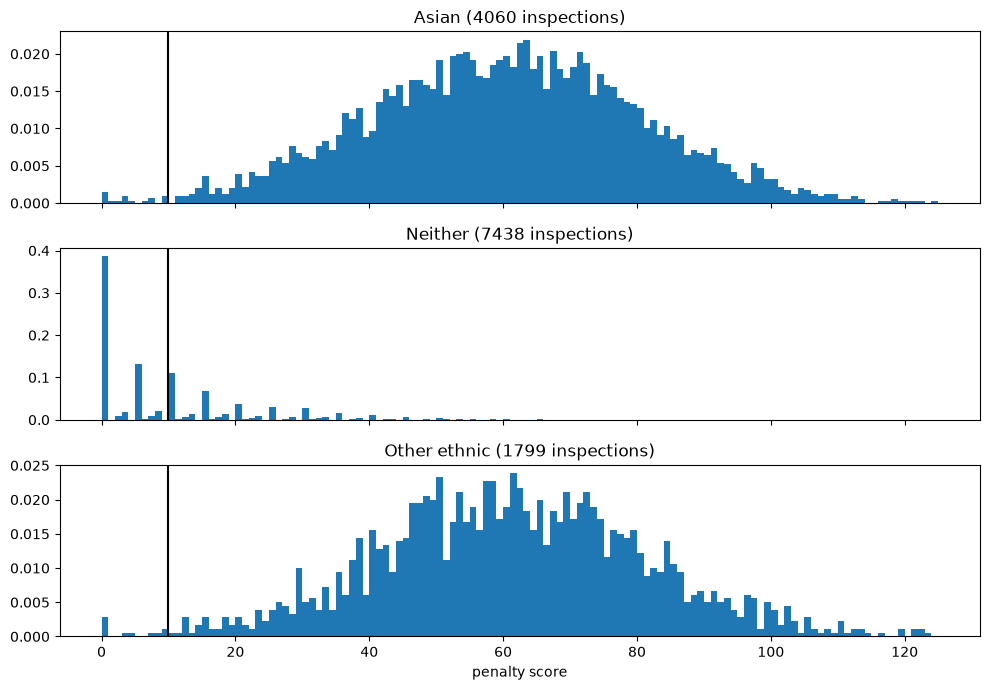

In [9]:
display(df.groupby("group").agg(
    restaurants=("restaurant_id", "nunique"),
    inspections=("score", "size"),
    mean_score=("score", "mean"),
    mean_prev_score=("prev_score", "mean"),
    share_scoring_0=("score", lambda s: (s == 0).mean()),
    share_serious=("serious", "mean"),
))

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, (name, g) in zip(axes, df.groupby("group")):
    ax.hist(g.score, bins=range(0, 126), density=True)
    ax.axvline(10, color="black")
    ax.set_title(f"{name} ({len(g)} inspections)")
axes[-1].set_xlabel("penalty score")
plt.tight_layout()
plt.show()

The gap is substantial. Asian and Other ethnic restaurants average about 60 points and almost never score 0, and 99.5% and 99.4% of their inspections are serious. The Neither group averages 10 points, scores 0 in 39% of inspections, and is serious 42% of the time. The shapes differ too: the Neither histogram has the spikes at 0, 5, 10 and so on, while the other two form smooth humps centered near 60.

### 2.2 Are the scores recorded the same way for every group?

The gap above is far bigger than I would expect from real differences between kitchens, so before modeling I checked whether the two sets of rows behave like the same kind of record:

1. **Does the file agree with itself?** When an inspection period starts on the day the previous one ended, the "previous score" column should equal the score the file records for that earlier inspection. Real differences between restaurants, or biased inspectors, would change the scores written down, but not this bookkeeping.
2. **Do a restaurant's scores track each other?** We saw that scores stick to restaurants. Within each group, I check whether a score tracks the same restaurant's earlier score, and whether the "previous score" column tracks either one. This also checks for a leak: if the "previous score" column secretly held the current score, it would track the current score much more closely than the real earlier score does.

In [10]:
# pair each inspection with the same restaurant's previous row in the file
d = df[["restaurant_id", "inspection_date", "period_start", "score", "prev_score", "group"]].sort_values(["restaurant_id", "inspection_date"])
d["earlier_score"] = d.groupby("restaurant_id").score.shift()
d["earlier_date"] = d.groupby("restaurant_id").inspection_date.shift()
pairs = d[d.period_start == d.earlier_date].copy()  # back-to-back periods only

pairs["matches"] = pairs.prev_score == pairs.earlier_score
print(pairs.groupby("group").matches.agg(["mean", "size"]).round(3))
pairs["earlier_band"] = pd.cut(pairs.earlier_score, [-1, 20, 45, 200])
pairs.groupby(["earlier_band", "group"], observed=True).matches.mean().unstack().round(3)

               mean  size
group                    
Asian         0.013  3137
Neither       0.951  5709
Other ethnic  0.013  1346


group,Asian,Neither,Other ethnic
earlier_band,,,
"(-1, 20]",0.000,0.956,0.000
"(20, 45]",0.014,0.928,0.008
"(45, 200]",0.013,0.930,0.014


In [11]:
# how often scores land on a multiple of 5, by score range
nz = df.loc[df.score > 0, ["score", "group"]].copy()
nz["multiple_of_5"] = nz.score % 5 == 0
nz["score_band"] = pd.cut(nz.score, [0, 20, 45, 200])
nz.groupby(["score_band", "group"], observed=True).multiple_of_5.mean().unstack().round(3)

group,Asian,Neither,Other ethnic
score_band,,,
"(0, 20]",0.333,0.765,0.282
"(20, 45]",0.202,0.658,0.257
"(45, 200]",0.196,0.483,0.190


In [12]:
pairs.groupby("group")[["score", "earlier_score", "prev_score"]].corr().round(3)

score  earlier_score  prev_score
group                                                       
Asian        score          1.000         -0.003      -0.026
             earlier_score -0.003          1.000      -0.016
             prev_score    -0.026         -0.016       1.000
Neither      score          1.000          0.245       0.245
             earlier_score  0.245          1.000       0.921
             prev_score     0.245          0.921       1.000
Other ethnic score          1.000          0.002      -0.066
             earlier_score  0.002          1.000      -0.007
             prev_score    -0.066         -0.007       1.000

- **The file disagrees with itself for two groups only.** For Neither restaurants, the "previous score" column matches the file's earlier score in 95.1% of back-to-back pairs. For Asian and Other ethnic restaurants it matches in 1.3%. The gap holds at every score level (after an earlier score of 46 or more: 93% against about 1%).
- **Only the Neither scores bunch.** Neither scores are multiples of 5 far more often than chance in every range. Above 20, where nearly all of their scores fall, Asian and Other ethnic scores are multiples of 5 only 19% to 26% of the time.
- **Only the Neither scores persist.** For Neither restaurants, a score tracks the same restaurant's earlier score (correlation 0.25), and the "previous score" column tracks the file's earlier score closely (0.92). For Asian and Other ethnic restaurants every correlation is essentially zero (between -0.07 and 0.00): a restaurant's score says nothing about its next one. This also rules out a leak: the "previous score" column never tracks the current score more than the real earlier score does.

I think real differences between kitchens would not produce this, and neither would biased inspectors on their own. Bias could make a group's scores higher and noisier, but it would not make the file's own columns disagree with each other. The two groups look instead as if their scores had been replaced with random numbers centered near 60. I can't tell from the file where that happened: in the original records, in processing, or in preparing this exercise. A direct check would be to compare a sample of rows with the source data or with King County's public inspection records.

## 3. Predicting serious violations

The model only gets what's known before an inspection: the last score, the average of earlier scores, days since the last inspection, Yelp activity since then, zip code and the cuisine flags. A separate model uses the review text. I train on 2006 to 2010, pick settings and calibrate on 2011, and test once on 2012 to early 2013, which is how this would actually be used.

I don't use accuracy, since calling everything serious is already about two thirds right. Instead I look at AUC (the chance a serious inspection gets ranked above a non-serious one, where 0.5 is a coin flip) and precision in the top 20% (if the department could only do the riskiest fifth of inspections, how many would find a serious violation). I also show everything for the Neither group alone, because the cuisine flag nearly decides the label for the other two.

Besides logistic regression, boosting and the text model, I compare against three simple rules: random (what equal visits amount to), ranking by last score, and putting Asian and Other ethnic restaurants first.

In [13]:
df["days_since_prev"] = (df.inspection_date - df.period_start).dt.days
df["zip_code"] = df.zip_code.astype("category")

history = ["prev_score", "avg_prev_score", "days_since_prev"]
yelp = ["review_count", "non_positive_review_count", "avg_rating"]
features = history + yelp + ["zip_code", "asian", "ethnic"]

train = df[df.inspection_date < "2011-01-01"]
valid = df[(df.inspection_date >= "2011-01-01") & (df.inspection_date < "2012-01-01")]
test = df[df.inspection_date >= "2012-01-01"]
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(name, part.inspection_date.min().date(), "to", part.inspection_date.max().date(),
          len(part), "rows,", round(part.serious.mean(), 3), "serious")

train 2006-01-03 to 2010-12-30 7053 rows, 0.681 serious
valid 2011-01-03 to 2011-12-30 2578 rows, 0.653 serious
test 2012-01-03 to 2013-02-08 3666 rows, 0.676 serious


In [14]:
def auc(model, data, cols):
    return roc_auc_score(data.serious, model.predict_proba(data[cols])[:, 1])

def logistic(C):
    numbers = history + yelp + ["asian", "ethnic"]
    prep = make_column_transformer((StandardScaler(), numbers), (OneHotEncoder(handle_unknown="ignore"), ["zip_code"]))
    return make_pipeline(prep, LogisticRegression(C=C, max_iter=2000))

def boosting(lr, leaves):
    # no early stopping, so results don't change with data size
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, early_stopping=False, random_state=0)

def text_model(C):
    words = TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", stop_words="english", min_df=5,
                            max_features=20000, sublinear_tf=True, dtype=np.float32)
    return make_pipeline(words, LogisticRegression(C=C, max_iter=2000))

# try a few settings for each model on 2011 and keep the best one
scores = {C: auc(logistic(C).fit(train[features], train.serious), valid, features) for C in [0.001, 0.01, 0.1, 1]}
print("logistic, by C:", {k: round(v, 3) for k, v in scores.items()})
logit = logistic(max(scores, key=scores.get)).fit(train[features], train.serious)

scores = {}
for lr in [0.02, 0.05, 0.1]:
    for leaves in [7, 15, 31]:
        scores[lr, leaves] = auc(boosting(lr, leaves).fit(train[features], train.serious), valid, features)
print("boosting, by (learning rate, leaves):", {k: round(v, 3) for k, v in scores.items()})
best_boosting = max(scores, key=scores.get)
gbm = boosting(*best_boosting).fit(train[features], train.serious)

scores = {C: auc(text_model(C).fit(train.review_text, train.serious), valid, "review_text") for C in [0.1, 1, 10]}
print("text, by C:", {k: round(v, 3) for k, v in scores.items()})
text = text_model(max(scores, key=scores.get)).fit(train.review_text, train.serious)

logistic, by C: {0.001: 0.877, 0.01: 0.878, 0.1: 0.871, 1: 0.867}


boosting, by (learning rate, leaves): {(0.02, 7): 0.871, (0.02, 15): 0.873, (0.02, 31): 0.871, (0.05, 7): 0.872, (0.05, 15): 0.872, (0.05, 31): 0.872, (0.1, 7): 0.87, (0.1, 15): 0.872, (0.1, 31): 0.868}


text, by C: {0.1: 0.828, 1: 0.837, 10: 0.828}


In [15]:
models = {"Logistic regression": (logit, features), "Gradient boosting": (gbm, features), "Review text": (text, "review_text")}
valid_p = {name: model.predict_proba(valid[cols])[:, 1] for name, (model, cols) in models.items()}
test_p = {name: model.predict_proba(test[cols])[:, 1] for name, (model, cols) in models.items()}
rankings = {"Previous score": test.prev_score.values, "Cuisine flag only": test.ethnic.values, **test_p}

y = test.serious.values
neither = (test.group == "Neither").values
subsets = {"All inspections": np.ones(len(test), bool), "Neither only": neither}

print("always guessing serious:", round(y.mean(), 3))
print("Neither:", round(neither.mean(), 3), "of test rows,", round(y[neither].mean(), 3), "serious")
print("Asian/Other ethnic:", round((~neither).mean(), 3), "of test rows,", round(y[~neither].mean(), 3), "serious")
for year, data, p in [("2011", valid, valid_p["Gradient boosting"]), ("test", test, test_p["Gradient boosting"])]:
    flagged = (data.group != "Neither").values
    print(f"boosting {year}: {len(np.unique(p[flagged]))} distinct value(s) for Asian/Other ethnic "
          f"({p[flagged].max():.3f}), highest for Neither {p[~flagged].max():.3f}")

always guessing serious: 0.676
Neither: 0.542 of test rows, 0.405 serious
Asian/Other ethnic: 0.458 of test rows, 0.997 serious
boosting 2011: 1 distinct value(s) for Asian/Other ethnic (0.953), highest for Neither 0.799
boosting test: 1 distinct value(s) for Asian/Other ethnic (0.953), highest for Neither 0.795


Results on the test years. The intervals resample whole restaurants, since a restaurant's inspections are related.

In [16]:
def order(score):
    # highest first, ties broken at random
    tiebreak = np.random.default_rng(0).random(len(score))
    return np.lexsort((tiebreak, -np.asarray(score, float)))
def top_share(score, share):
    picked = np.zeros(len(score), bool)
    picked[order(score)[:round(share * len(score))]] = True
    return picked
def auc_interval(y, score, restaurants, n=500):
    # resample whole restaurants: a restaurant drawn k times counts k times
    ids, codes = np.unique(restaurants, return_inverse=True)
    rng = np.random.default_rng(0)
    aucs = []
    for _ in range(n):
        weights = np.bincount(rng.integers(len(ids), size=len(ids)), minlength=len(ids))[codes]
        aucs.append(roc_auc_score(y, score, sample_weight=weights))
    return np.percentile(aucs, [2.5, 97.5])

rows = []
for subset, m in subsets.items():
    for name, s in rankings.items():
        low, high = auc_interval(y[m], s[m], test.restaurant_id.values[m])
        rows.append({"subset": subset, "ranking": name, "AUC": roc_auc_score(y[m], s[m]), "95% low": low,
                     "95% high": high, "precision top 20%": y[m][top_share(s[m], 0.2)].mean()})
pd.DataFrame(rows).set_index(["subset", "ranking"])

AUC  95% low  95% high  \
subset          ranking                                         
All inspections Previous score       0.870    0.856     0.884   
                Cuisine flag only    0.836    0.823     0.850   
                Logistic regression  0.885    0.872     0.897   
                Gradient boosting    0.886    0.875     0.899   
                Review text          0.845    0.829     0.860   
Neither only    Previous score       0.639    0.613     0.662   
                Cuisine flag only    0.500    0.500     0.500   
                Logistic regression  0.651    0.626     0.677   
                Gradient boosting    0.657    0.631     0.684   
                Review text          0.576    0.549     0.603   

                                     precision top 20%  
subset          ranking                                 
All inspections Previous score                   0.988  
                Cuisine flag only                0.996  
                Logistic regression              0.999  
                Gradient boosting                0.996  
                Review text                      0.993  
Neither only    Previous score                   0.594  
                Cuisine flag only                0.418  
                Logistic regression              0.594  
                Gradient boosting                0.617  
                Review text                      0.489

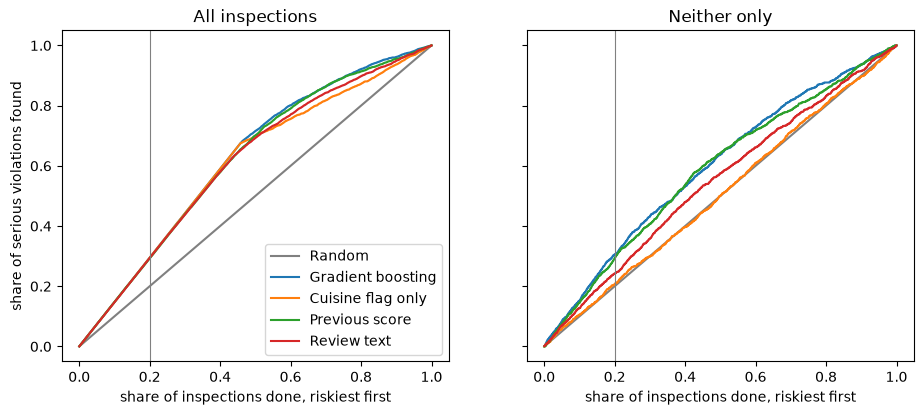

In [17]:
def capture(weights, score):
    w = np.asarray(weights, float)[order(score)]
    return np.arange(1, len(w) + 1) / len(w), np.cumsum(w) / w.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, (subset, m) in zip(axes, subsets.items()):
    ax.plot([0, 1], [0, 1], color="gray", label="Random")
    for name in ["Gradient boosting", "Cuisine flag only", "Previous score", "Review text"]:
        ax.plot(*capture(y[m], rankings[name][m]), label=name)
    ax.axvline(0.2, color="gray", linewidth=0.8)
    ax.set_title(subset)
    ax.set_xlabel("share of inspections done, riskiest first")
axes[0].set_ylabel("share of serious violations found")
axes[0].legend()
plt.show()

1. Most of the overall AUC is the cuisine flag. Boosting gets 0.886 and last score 0.870, but the flag alone already gets 0.836. Every ranking puts the Asian and Other ethnic inspections first and 99.7% of those are serious, so precision in the top 20% is about 99% for all of them. Boosting even gives every one of those inspections the same probability (0.953), so their order among themselves is just the random tie-break.
2. Within Neither it's more modest. Boosting gets 0.657 against 0.639 for last score, and its top 20% finds a serious violation 62% of the time against 40% at random.
3. Logistic regression and boosting are tied, and the text model is worse than just using the last score.

I use boosting for the rest mostly for convenience. Logistic regression was actually slightly ahead on 2011 (0.878 vs 0.873), but boosting takes any subset of inputs without preprocessing, which I need further down. The settings barely mattered (2011 AUC moved by 0.011 at most).

### Calibration

A ranking is enough to decide who goes first, but if the department uses "70% risk" to set how often to visit, it should mean 70%. I fit an isotonic map (a curve that only goes up) from 2011 predictions to 2011 outcomes and apply it to the test years. It never reverses the order of two inspections, so the rankings above still hold.

In [18]:
calibrated = {}
for name in test_p:
    iso = IsotonicRegression(out_of_bounds="clip").fit(valid_p[name], valid.serious)
    calibrated[name] = iso.predict(test_p[name])

rows = []
for name in test_p:
    for subset, m in subsets.items():
        rows.append({"model": name, "subset": subset, "Brier before": brier_score_loss(y[m], test_p[name][m]),
                     "Brier after": brier_score_loss(y[m], calibrated[name][m])})
display(pd.DataFrame(rows).set_index(["model", "subset"]))

# baseline: give everyone their subset's serious rate from 2011
valid_neither = (valid.group == "Neither").values
print("base rate, all:", round(brier_score_loss(y, np.full(len(y), valid.serious.mean())), 3))
print("base rate, Neither:", round(brier_score_loss(y[neither], np.full(neither.sum(), valid.serious[valid_neither].mean())), 3))

Brier before  Brier after
model               subset                                    
Logistic regression All inspections         0.125        0.124
                    Neither only            0.228        0.226
Gradient boosting   All inspections         0.126        0.123
                    Neither only            0.228        0.224
Review text         All inspections         0.150        0.145
                    Neither only            0.260        0.248

base rate, all: 0.22
base rate, Neither: 0.241


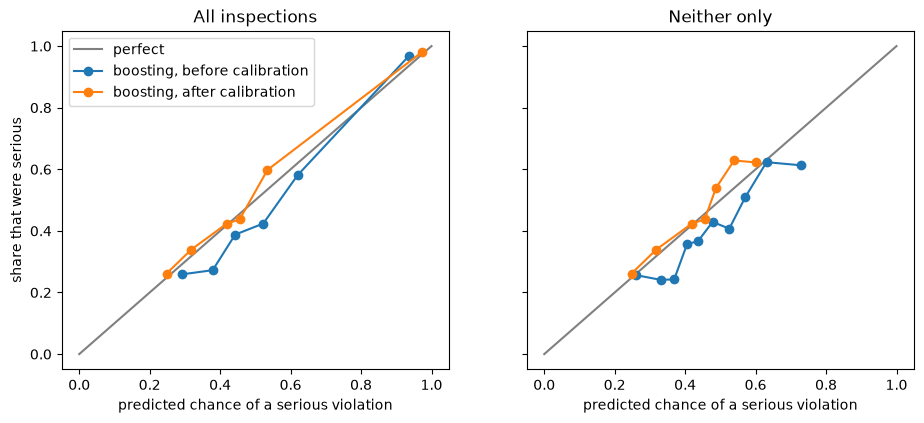

All inspections                         Neither only                        
           before            after              before            after       
        predicted actual predicted actual    predicted actual predicted actual
0            0.29   0.26      0.25   0.26         0.26   0.26      0.25   0.26
1            0.38   0.27      0.32   0.34         0.33   0.24      0.32   0.34
2            0.44   0.39      0.42   0.42         0.37   0.24      0.42   0.42
3            0.52   0.42      0.46   0.44         0.41   0.36      0.46   0.44
4            0.62   0.58      0.53   0.60         0.44   0.37      0.49   0.54
5            0.94   0.97      0.97   0.98         0.48   0.43      0.54   0.63
6             NaN    NaN       NaN    NaN         0.53   0.41      0.60   0.62
7             NaN    NaN       NaN    NaN         0.57   0.51       NaN    NaN
8             NaN    NaN       NaN    NaN         0.63   0.62       NaN    NaN
9             NaN    NaN       NaN    NaN         0.73   0.61       NaN    NaN

In [19]:
points = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (subset, m) in zip(axes, subsets.items()):
    ax.plot([0, 1], [0, 1], color="gray", label="perfect")
    for stage, p in [("before", test_p["Gradient boosting"]), ("after", calibrated["Gradient boosting"])]:
        actual, predicted = calibration_curve(y[m], p[m], n_bins=10, strategy="quantile")
        points[subset, stage] = pd.DataFrame({"predicted": predicted, "actual": actual})
        ax.plot(predicted, actual, marker="o", label=f"boosting, {stage} calibration")
    ax.set_title(subset)
    ax.set_xlabel("predicted chance of a serious violation")
axes[0].set_ylabel("share that were serious")
axes[0].legend()
plt.show()
pd.concat(points, axis=1).round(2)

Before calibration boosting overstates middling risk. Neither inspections it gave a 33% to 37% chance were serious 24% of the time. After calibration most bins are within 2 points, though a few middle bins are still 5 to 9 points low. The Brier score (the average squared gap between predicted chance and outcome) within Neither goes from 0.228 to 0.224, against 0.241 for just using the base rate. Because boosting gives all Asian and Other ethnic inspections the same value, the map for Neither is effectively fitted on Neither alone. The text model has the worst Brier scores, and within Neither it stays worse than the base rate even after calibration.

### What the model relies on

The prompt says some variables are much more predictive than others, so I refit boosting on one group of inputs at a time, and again with one group left out. The last column is the fairness question: how much of the top 20% is Asian or Other ethnic?

In [20]:
input_groups = {"history": history, "Yelp": yelp, "zip code": ["zip_code"], "cuisine flags": ["asian", "ethnic"]}
tries = {"all inputs": features}
for g, cols in input_groups.items():
    tries["only " + g] = cols
    tries["all but " + g] = [c for c in features if c not in cols]

rows = []
for label, cols in tries.items():
    model = boosting(*best_boosting).fit(train[cols], train.serious)
    p = model.predict_proba(test[cols])[:, 1]
    rows.append({"inputs": label, "AUC 2011": auc(model, valid, cols), "AUC test": roc_auc_score(y, p),
                 "AUC test, Neither": roc_auc_score(y[neither], p[neither]),
                 "Asian/Other ethnic share of top 20%": (~neither)[top_share(p, 0.2)].mean()})
pd.DataFrame(rows).set_index("inputs")

,AUC 2011,AUC test,"AUC test, Neither",Asian/Other ethnic share of top 20%
inputs,,,,
all inputs,0.873,0.886,0.657,1.000
only history,0.875,0.894,0.685,0.997
all but history,0.848,0.850,0.545,1.000
only Yelp,0.527,0.515,0.504,0.467
all but Yelp,0.870,0.888,0.661,1.000
only zip code,0.612,0.637,0.597,0.572
all but zip code,0.879,0.894,0.681,1.000
only cuisine flags,0.826,0.835,0.500,1.000
all but cuisine flags,0.872,0.889,0.671,0.997


In [21]:
weights = pd.Series(text[-1].coef_[0], index=text[0].get_feature_names_out()).sort_values()
print("toward serious:", ", ".join(weights.index[::-1][:15]))
print("toward not serious:", ", ".join(weights.index[:15]))

toward serious: rice, sushi, mexican, pho, chinese, teriyaki, thai, tofu, restaurant, vietnamese, taco, ethiopian, chicken, food, rolls
toward not serious: pizza, subway, burger, sandwich, pie, wine, potato, cup, caesar, chicago, coffee, fries, cheese, selection, potatoes


History alone does as well as everything together (0.894 overall and 0.685 within Neither), and that was already true on 2011. Yelp on its own is a coin flip. Leaving out the cuisine flags changes nothing. The model still fills 99.7% of its top 20% with Asian or Other ethnic restaurants, which are 45.8% of test inspections, because their history columns are inflated too.

The text model is mostly a cuisine detector. The words pushing toward serious are rice, sushi, mexican, pho, chinese, teriyaki and thai, and the ones pushing away are pizza, subway, burger, sandwich and pie.